# Homework X2: MLP for MNIST Classification

**Name:** 陈一铭  
**Student ID:** 2024012657  
**Course:** Introduction to Deep Learning

I use NumPy to implement a one-hidden-layer MLP, backpropagation, and mini-batch SGD. The five required functions are completed below. The experiments use the fixed 50,000/10,000/10,000 split and seed 2026.

**Setup:** Python 3, NumPy, and Matplotlib. Put the course-supplied MNIST files in `data/mnist_data/` at the project root. The original layout, with the notebook, loader, and `mnist_data/` together, is also supported. Dataset files are not included in the submission.


In [1]:
import csv
import hashlib
import json
import os
import platform
import sys
from datetime import datetime, timezone
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np

SEED = 2026
EPOCHS = 8
BATCH_SIZE = 256

# Start the kernel in this project root or its codes/ folder.
candidate = Path.cwd().resolve()
if candidate.name.lower() == 'codes':
    candidate = candidate.parent
if (candidate / 'codes' / 'mnist_data_loader.py').is_file():
    PROJECT_ROOT = candidate
    CODE_DIR = candidate / 'codes'
    DATA_DIR = candidate / 'data' / 'mnist_data'
elif (candidate / 'mnist_data_loader.py').is_file():
    PROJECT_ROOT = candidate
    CODE_DIR = candidate
    DATA_DIR = candidate / 'mnist_data'
else:
    raise FileNotFoundError('Start from this project root or its codes/ folder.')
if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))
from mnist_data_loader import load_mnist

IMAGE_DIR = PROJECT_ROOT / 'images'
REPORT_DIR = PROJECT_ROOT / 'report'
IMAGE_DIR.mkdir(exist_ok=True)
REPORT_DIR.mkdir(exist_ok=True)
plt.rcParams.update({'figure.facecolor': 'white', 'axes.facecolor': 'white',
                     'savefig.facecolor': 'white', 'text.color': 'black',
                     'axes.labelcolor': 'black', 'xtick.color': 'black',
                     'ytick.color': 'black'})
print('Python:', platform.python_version())
print('NumPy:', np.__version__, '| Matplotlib:', matplotlib.__version__)
print('Data layout:', 'project' if CODE_DIR.name == 'codes' else 'original')


Python: 3.12.14
NumPy: 2.3.5 | Matplotlib: 3.10.8
Data layout: project


In [2]:
images_all, labels_all, images_test, labels_test = load_mnist(DATA_DIR)
assert images_all.shape == (60_000, 28, 28)
assert images_test.shape == (10_000, 28, 28)
X_all = images_all.reshape(60_000, 784).astype(np.float32) / 255.0
X_test = images_test.reshape(10_000, 784).astype(np.float32) / 255.0
y_all, y_test = labels_all, labels_test

# Identical split recipe to HW1: 50,000 training and 10,000 validation.
permutation = np.random.default_rng(SEED).permutation(60_000)
train_indices, val_indices = permutation[:50_000], permutation[50_000:]
X_train, y_train = X_all[train_indices], y_all[train_indices]
X_val, y_val = X_all[val_indices], y_all[val_indices]
del images_test, X_all
assert X_train.shape == (50_000, 784) and X_val.shape == (10_000, 784)
assert X_test.shape == (10_000, 784)
print('train / validation / test:', X_train.shape, X_val.shape, X_test.shape)


train / validation / test: (50000, 784) (10000, 784) (10000, 784)


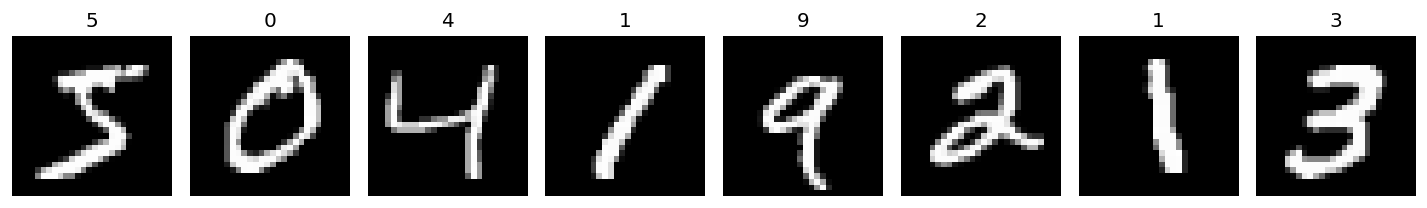

In [3]:
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, sample, label in zip(axes, images_all[:8], labels_all[:8]):
    ax.imshow(sample, cmap='gray', vmin=0, vmax=255)
    ax.set_title(str(label))
    ax.axis('off')
fig.tight_layout()
fig.savefig(IMAGE_DIR / 'mnist_samples.png', dpi=300, bbox_inches='tight')
plt.show()
del images_all


## 1. Model, objective, and function outputs

For a batch $X$ with shape $(B,784)$, use $W_1:(H,784)$, $b_1:(H,)$, $W_2:(10,H)$, and $b_2:(10,)$. The forward pass is $A=XW_1^\top+b_1$, $Q=\max(0,A)$, $Z=QW_2^\top+b_2$, and $P=\operatorname{softmax}(Z)$. Minimize mean cross-entropy plus $\lambda(\lVert W_1\rVert_F^2+\lVert W_2\rVert_F^2)/2$. The two biases are not regularized. Use ReLU derivative 0 at exactly 0.

| Function | Required output |
|---|---|
| `init_params(D, H, C, seed)` | Dictionary with `W1` shape `(H,D)`, `b1` `(H,)`, `W2` `(C,H)`, `b2` `(C,)`; all NumPy arrays. |
| `forward(X, params)` | Tuple `(A, Q, Z, P)` with shapes `(B,H)`, `(B,H)`, `(B,C)`, `(B,C)`; each row of `P` sums to 1. |
| `loss_and_grad_batch(X, y, params, reg)` | `(loss, grads)`: finite Python `float` plus a dictionary with the same keys and array shapes as `params`. |
| `predict(X, params)` | Integer NumPy array of shape `(B,)`, with class labels 0–9. |
| `train_mlp(...)` | `(params, history)`; `history` has `train_loss`, `train_accuracy`, and `val_accuracy`, each a list of length `epochs`. |

The supplied `evaluate` helper returns `(loss, accuracy)`, both Python floats. For stable cross-entropy, use shifted logits and `log(sum(exp(shifted))) - shifted[y]`; directly taking `log(P[y])` can fail when a probability rounds to zero.


In [4]:
def init_params(input_size, hidden_size, num_classes=10, seed=SEED):
    """Gaussian weights and zero biases, with class weights stored in rows."""
    rng = np.random.default_rng(seed)
    return {
        'W1': (rng.normal(size=(hidden_size, input_size))
               * np.sqrt(2.0 / input_size)).astype(np.float32),
        'b1': np.zeros(hidden_size, dtype=np.float32),
        'W2': (rng.normal(size=(num_classes, hidden_size))
               * np.sqrt(1.0 / hidden_size)).astype(np.float32),
        'b2': np.zeros(num_classes, dtype=np.float32),
    }


In [5]:
def forward(X, params):
    """Return hidden preactivations, ReLU activations, logits, probabilities."""
    A = X @ params['W1'].T + params['b1']
    Q = np.maximum(0, A)
    Z = Q @ params['W2'].T + params['b2']
    shifted = Z - np.max(Z, axis=1, keepdims=True)
    exp_shifted = np.exp(shifted)
    P = exp_shifted / np.sum(exp_shifted, axis=1, keepdims=True)
    return A, Q, Z, P


In [6]:
def loss_and_grad_batch(X, y, params, reg):
    """Stable mean cross-entropy plus L2 on W1 and W2 only."""
    if X.shape[0] == 0:
        raise ValueError('A batch must be nonempty')
    A, Q, Z, P = forward(X, params)
    batch_size = len(X)
    shifted = Z - np.max(Z, axis=1, keepdims=True)
    nll = np.log(np.sum(np.exp(shifted), axis=1)) - shifted[np.arange(batch_size), y]
    penalty = 0.5 * reg * (np.sum(params['W1'] ** 2) + np.sum(params['W2'] ** 2))
    loss = float(np.mean(nll) + penalty)

    dZ = P.copy()
    dZ[np.arange(batch_size), y] -= 1.0
    dZ /= batch_size
    dA = (dZ @ params['W2']) * (A > 0)
    grads = {
        'W1': dA.T @ X + reg * params['W1'],
        'b1': np.sum(dA, axis=0),
        'W2': dZ.T @ Q + reg * params['W2'],
        'b2': np.sum(dZ, axis=0),
    }
    return loss, grads


In [7]:
def predict(X, params):
    """Return the class with the largest logit in each row."""
    Z = forward(X, params)[2]
    return np.argmax(Z, axis=1)


In [8]:
def evaluate(X, y, params, reg=0.0, chunk_size=2048):
    """Return (regularized mean loss, accuracy), both Python floats."""
    if len(X) == 0:
        raise ValueError('The evaluation set must be nonempty')
    total_nll, correct = 0.0, 0
    for start in range(0, len(X), chunk_size):
        X_part = X[start:start + chunk_size]
        y_part = y[start:start + chunk_size]
        Z = forward(X_part, params)[2]
        shifted = Z - np.max(Z, axis=1, keepdims=True)
        total_nll += float(np.sum(
            np.log(np.sum(np.exp(shifted), axis=1))
            - shifted[np.arange(len(X_part)), y_part]))
        correct += int(np.sum(np.argmax(Z, axis=1) == y_part))
    penalty = 0.5 * reg * (
        np.sum(params['W1'] ** 2) + np.sum(params['W2'] ** 2))
    return float(total_nll / len(X) + penalty), correct / len(X)


## 2. Check your implementation

The following cell checks initialization, forward computation, loss, gradients, and prediction. The tests check output shapes, extreme logits, prediction, and analytic gradients against central finite differences on a tiny model. Loops in this diagnostic checker are allowed.


In [9]:
shape_params = init_params(5, 3, 4, seed=SEED)
assert {key: value.shape for key, value in shape_params.items()} == {
    'W1': (3, 5), 'b1': (3,), 'W2': (4, 3), 'b2': (4,)}
A, Q, Z, P = forward(np.zeros((2, 5), dtype=np.float32), shape_params)
assert (A.shape, Q.shape, Z.shape, P.shape) == ((2, 3), (2, 3), (2, 4), (2, 4))
assert np.allclose(P.sum(axis=1), 1.0) and np.all(P >= 0)

extreme = {'W1': np.array([[1.0]]), 'b1': np.array([0.0]),
           'W2': np.array([[1000.0], [-1000.0]]), 'b2': np.zeros(2)}
extreme_loss, _ = loss_and_grad_batch(
    np.array([[1.0]]), np.array([1]), extreme, 0.0)
assert np.isfinite(extreme_loss) and extreme_loss > 1000.0

check_rng = np.random.default_rng(7)
X_check = check_rng.normal(scale=0.2, size=(4, 5))
y_check = np.array([0, 2, 1, 2])
check_params = {
    'W1': check_rng.normal(scale=0.1, size=(3, 5)),
    'b1': np.array([0.5, 0.6, 0.7]),
    'W2': check_rng.normal(scale=0.1, size=(3, 3)),
    'b2': check_rng.normal(scale=0.1, size=3),
}
reg_check = 0.03
_, analytic = loss_and_grad_batch(X_check, y_check, check_params, reg_check)
assert np.array_equal(predict(X_check, check_params),
                      np.argmax(forward(X_check, check_params)[2], axis=1))

step = 1e-5
largest_error = 0.0
for name, values in check_params.items():
    assert analytic[name].shape == values.shape
    for index in np.ndindex(values.shape):
        original = values[index]
        values[index] = original + step
        plus = loss_and_grad_batch(X_check, y_check, check_params, reg_check)[0]
        values[index] = original - step
        minus = loss_and_grad_batch(X_check, y_check, check_params, reg_check)[0]
        values[index] = original
        numeric = (plus - minus) / (2 * step)
        largest_error = max(largest_error, abs(numeric - analytic[name][index]))
assert largest_error < 1e-6, largest_error
print('Largest absolute gradient error:', largest_error)
print('All checks passed.')


gradient_checks = {'supplied_largest_absolute_error': float(largest_error),
                   'extreme_logit_loss': float(extreme_loss)}


Largest absolute gradient error: 2.1398785521320463e-11
All checks passed.


In [10]:
mask_params = {name: values.copy() for name, values in check_params.items()}
mask_params['b1'][1] = -0.6
mask_A = forward(X_check, mask_params)[0]
assert np.all(mask_A[:, 1] < 0)
_, analytic_mask = loss_and_grad_batch(X_check, y_check, mask_params, reg_check)
mask_errors = {}
for name, values in mask_params.items():
    errors = []
    for index in np.ndindex(values.shape):
        original = values[index]
        values[index] = original + step
        plus = loss_and_grad_batch(X_check, y_check, mask_params, reg_check)[0]
        values[index] = original - step
        minus = loss_and_grad_batch(X_check, y_check, mask_params, reg_check)[0]
        values[index] = original
        errors.append(abs((plus - minus) / (2 * step) - analytic_mask[name][index]))
    mask_errors[name] = float(max(errors))
    assert mask_errors[name] < 1e-6

# At A == 0, the prescribed ReLU derivative is zero.
zero_params = {'W1': np.zeros((2, 3)), 'b1': np.zeros(2),
               'W2': np.array([[1.0, -2.0], [-1.0, 2.0]]),
               'b2': np.zeros(2)}
_, zero_grads = loss_and_grad_batch(np.ones((1, 3)), np.array([0]), zero_params, 0.0)
assert np.array_equal(zero_grads['W1'], np.zeros((2, 3)))
assert np.array_equal(zero_grads['b1'], np.zeros(2))
gradient_checks['active_inactive_relu_errors'] = mask_errors
gradient_checks['relu_derivative_at_zero'] = 'passed'
print('Gradient errors with active and inactive ReLU units:', mask_errors)
print('ReLU mask checks passed.')


Gradient errors with active and inactive ReLU units: {'W1': 2.1913352209190773e-11, 'b1': 1.0849319706518479e-11, 'W2': 1.591884089824358e-11, 'b2': 6.43896047591852e-12}
ReLU mask checks passed.


## 3. Mini-batch training

Only training images enter parameter updates. The supplied loop records full training loss and training/validation accuracy after every epoch; `history` must contain one value per epoch for each metric.


In [11]:
def train_mlp(X_train, y_train, X_val, y_val, *, hidden_size,
              learning_rate, reg=1e-4, epochs=3, batch_size=256, seed=SEED):
    """Return (params, history).

    params is the trained parameter dictionary. history has the keys
    'train_loss', 'train_accuracy', 'val_accuracy'; each value is a list
    of Python floats with length epochs.
    """
    params = init_params(X_train.shape[1], hidden_size, 10, seed)
    rng = np.random.default_rng(seed)
    history = {'train_loss': [], 'train_accuracy': [], 'val_accuracy': []}
    for epoch in range(epochs):
        order = rng.permutation(len(X_train))
        for start in range(0, len(order), batch_size):
            indices = order[start:start + batch_size]
            _, grads = loss_and_grad_batch(
                X_train[indices], y_train[indices], params, reg)
            for name in params:
                params[name] -= learning_rate * grads[name]
        train_loss, train_acc = evaluate(X_train, y_train, params, reg)
        _, val_acc = evaluate(X_val, y_val, params)
        history['train_loss'].append(train_loss)
        history['train_accuracy'].append(train_acc)
        history['val_accuracy'].append(val_acc)
        print(f'epoch {epoch + 1:2d}/{epochs}: loss={train_loss:.4f}, '
              f'train acc={train_acc:.4f}, val acc={val_acc:.4f}')
    return params, history


## 4. Compare hyperparameters

These three runs compare two learning rates at width 32 and two widths at learning rate 0.10. Keep the split and seed fixed. Choose the model using validation accuracy only; do not inspect the test set here.


In [12]:
configs = [
    {'name': 'baseline', 'hidden_size': 32, 'learning_rate': 0.10, 'reg': 1e-4},
    {'name': 'smaller learning rate', 'hidden_size': 32, 'learning_rate': 0.03, 'reg': 1e-4},
    {'name': 'wider hidden layer', 'hidden_size': 64, 'learning_rate': 0.10, 'reg': 1e-4},
]
runs = {}
for config in configs:
    print('Configuration:', config['name'])
    params, history = train_mlp(
        X_train, y_train, X_val, y_val,
        hidden_size=config['hidden_size'],
        learning_rate=config['learning_rate'], reg=config['reg'],
        epochs=EPOCHS, batch_size=BATCH_SIZE, seed=SEED)
    runs[config['name']] = {'config': config, 'params': params, 'history': history}

print('configuration             width      lr   lambda  train acc   val acc')
for name, run in runs.items():
    cfg, h = run['config'], run['history']
    print(f"{name:26s} {cfg['hidden_size']:5d} {cfg['learning_rate']:7.3g} "
          f"{cfg['reg']:8.2g} {h['train_accuracy'][-1]:10.4f} "
          f"{h['val_accuracy'][-1]:9.4f}")
best_name = max(runs, key=lambda name: runs[name]['history']['val_accuracy'][-1])
print('Selected by final validation accuracy:', best_name)


Configuration: baseline
epoch  1/8: loss=0.4122, train acc=0.8855, val acc=0.8873
epoch  2/8: loss=0.3415, train acc=0.9032, val acc=0.9014
epoch  3/8: loss=0.3019, train acc=0.9147, val acc=0.9110
epoch  4/8: loss=0.2778, train acc=0.9220, val acc=0.9190
epoch  5/8: loss=0.2597, train acc=0.9265, val acc=0.9235
epoch  6/8: loss=0.2469, train acc=0.9311, val acc=0.9275
epoch  7/8: loss=0.2304, train acc=0.9357, val acc=0.9311
epoch  8/8: loss=0.2226, train acc=0.9382, val acc=0.9310
Configuration: smaller learning rate
epoch  1/8: loss=0.6983, train acc=0.8332, val acc=0.8293
epoch  2/8: loss=0.4866, train acc=0.8756, val acc=0.8732
epoch  3/8: loss=0.4145, train acc=0.8886, val acc=0.8859
epoch  4/8: loss=0.3767, train acc=0.8981, val acc=0.8935
epoch  5/8: loss=0.3542, train acc=0.9022, val acc=0.8981
epoch  6/8: loss=0.3379, train acc=0.9071, val acc=0.9024
epoch  7/8: loss=0.3242, train acc=0.9106, val acc=0.9073
epoch  8/8: loss=0.3143, train acc=0.9133, val acc=0.9094
Configurati

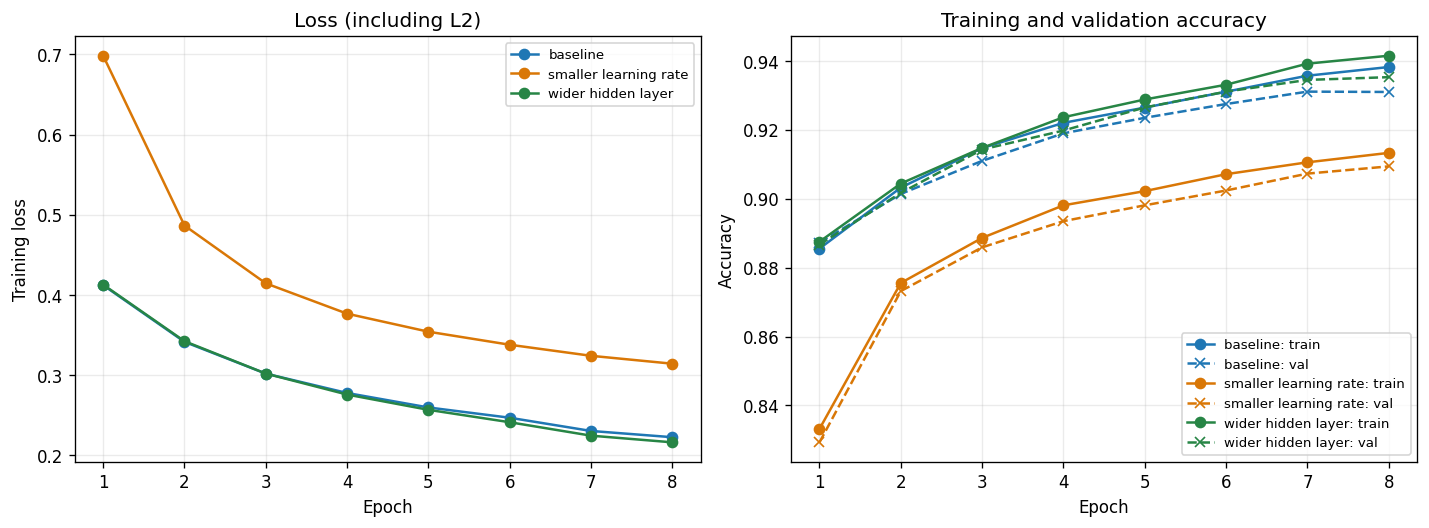

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
colors = ['#1f77b4', '#d97706', '#278545']
for (name, run), color in zip(runs.items(), colors):
    h = run['history']
    epoch_axis = np.arange(1, len(h['train_loss']) + 1)
    axes[0].plot(epoch_axis, h['train_loss'], marker='o', color=color, label=name)
    axes[1].plot(epoch_axis, h['train_accuracy'], marker='o', color=color,
                 label=f'{name}: train')
    axes[1].plot(epoch_axis, h['val_accuracy'], marker='x', linestyle='--',
                 color=color, label=f'{name}: val')
axes[0].set(xlabel='Epoch', ylabel='Training loss', title='Loss (including L2)')
axes[1].set(xlabel='Epoch', ylabel='Accuracy', title='Training and validation accuracy')
for ax in axes:
    ax.set_xticks(np.arange(1, EPOCHS + 1))
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(IMAGE_DIR / 'learning_curves.png', dpi=300, bbox_inches='tight')
plt.show()


## 5. One-time test evaluation

Run this only after selecting the configuration by validation accuracy. Do not change settings based on the test result.


In [14]:
# Prevent accidental repeated test evaluation in the same kernel.
if globals().get('_test_evaluation_done', False):
    raise RuntimeError('Test evaluation already finished. Use the recorded result.')
chosen = runs[best_name]
_test_evaluation_done = True
test_loss, test_accuracy = evaluate(X_test, y_test, chosen['params'])
print('Selected configuration:', best_name)
print(f"Final validation accuracy: {chosen['history']['val_accuracy'][-1]:.4f}")
print(f'Test accuracy: {test_accuracy:.4f}')
print(f'Test correct: {round(test_accuracy * len(y_test))} / {len(y_test)}')


Selected configuration: wider hidden layer
Final validation accuracy: 0.9353
Test accuracy: 0.9389
Test correct: 9389 / 10000


## 6. Saved experiment records

The next cell saves the settings, full epoch histories, implementation checks, and final test result. It reads the results already in memory and does not repeat test evaluation. Accuracies in the record files are fractions. The Markdown, LaTeX, and PDF reports are prepared separately from these recorded results.


In [15]:
summary_rows = []
epoch_rows = []
for name, run in runs.items():
    cfg, h = run['config'], run['history']
    summary_rows.append({
        'configuration': name, 'hidden_size': cfg['hidden_size'],
        'learning_rate': cfg['learning_rate'], 'reg': cfg['reg'],
        'epochs': len(h['train_loss']), 'batch_size': BATCH_SIZE,
        'train_loss': h['train_loss'][-1],
        'train_accuracy': h['train_accuracy'][-1],
        'val_accuracy': h['val_accuracy'][-1], 'selected': name == best_name,
        'test_accuracy': test_accuracy if name == best_name else '',
    })
    for epoch in range(len(h['train_loss'])):
        epoch_rows.append({
            'configuration': name, 'epoch': epoch + 1,
            'train_loss': h['train_loss'][epoch],
            'train_accuracy': h['train_accuracy'][epoch],
            'val_accuracy': h['val_accuracy'][epoch],
        })
for filename, rows in [('results.csv', summary_rows), ('epoch_results.csv', epoch_rows)]:
    with (REPORT_DIR / filename).open('w', newline='', encoding='utf-8') as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

data_checksums = {}
for filename in sorted(p.name for p in DATA_DIR.glob('*.gz')):
    data_checksums[filename] = hashlib.sha256((DATA_DIR / filename).read_bytes()).hexdigest()
record = {
    'export_time_utc': datetime.now(timezone.utc).isoformat(),
    'seed': SEED, 'split': {'train': len(y_train), 'validation': len(y_val), 'test': len(y_test)},
    'split_recipe': 'default_rng(2026).permutation(60000): first 50000 train, last 10000 validation',
    'train_indices_sha256': hashlib.sha256(train_indices.astype('<i8').tobytes()).hexdigest(),
    'val_indices_sha256': hashlib.sha256(val_indices.astype('<i8').tobytes()).hexdigest(),
    'data_sha256': data_checksums,
    'preprocessing': 'flatten 28x28 to 784; float32 / 255.0',
    'initialization': 'W1 normal std sqrt(2/784); W2 normal std sqrt(1/H); zero biases; float32',
    'epochs': EPOCHS, 'batch_size': BATCH_SIZE,
    'objective': 'mean cross-entropy + 0.5*reg*(sum(W1**2)+sum(W2**2)); no bias penalty',
    'optimizer': 'mini-batch SGD; fixed learning rate; seeded reshuffling each epoch',
    'selection_rule': 'highest final validation accuracy; first configured run wins ties',
    'implementation_checks': gradient_checks,
    'runs': {name: {'config': run['config'], 'history': run['history']} for name, run in runs.items()},
    'selected_configuration': best_name,
    'test_evaluations': 1, 'test_accuracy': test_accuracy, 'test_cross_entropy': test_loss,
    'test_correct': round(test_accuracy * len(y_test)),
    'environment': {'python': platform.python_version(), 'numpy': np.__version__,
                    'matplotlib': matplotlib.__version__, 'platform': platform.system(),
                    'blas_thread_environment': {key: os.environ.get(key) for key in
                                               ['OPENBLAS_NUM_THREADS', 'OMP_NUM_THREADS', 'MKL_NUM_THREADS']},
                    'execution_method': globals().get('EXECUTION_METHOD', 'Jupyter kernel')},
}
with (REPORT_DIR / 'experiment_record.json').open('w', encoding='utf-8') as stream:
    json.dump(record, stream, indent=2, ensure_ascii=False, allow_nan=False)
print('Saved: report/results.csv')
print('Saved: report/epoch_results.csv')
print('Saved: report/experiment_record.json')


Saved: report/results.csv
Saved: report/epoch_results.csv
Saved: report/experiment_record.json
